In [1]:
import torch

torch.manual_seed(42)

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [10]:
x = torch.linspace(-2, 2, 120).unsqueeze(1).to(device)

In [11]:
x

tensor([[-2.0000],
        [-1.9664],
        [-1.9328],
        [-1.8992],
        [-1.8655],
        [-1.8319],
        [-1.7983],
        [-1.7647],
        [-1.7311],
        [-1.6975],
        [-1.6639],
        [-1.6303],
        [-1.5966],
        [-1.5630],
        [-1.5294],
        [-1.4958],
        [-1.4622],
        [-1.4286],
        [-1.3950],
        [-1.3613],
        [-1.3277],
        [-1.2941],
        [-1.2605],
        [-1.2269],
        [-1.1933],
        [-1.1597],
        [-1.1261],
        [-1.0924],
        [-1.0588],
        [-1.0252],
        [-0.9916],
        [-0.9580],
        [-0.9244],
        [-0.8908],
        [-0.8571],
        [-0.8235],
        [-0.7899],
        [-0.7563],
        [-0.7227],
        [-0.6891],
        [-0.6555],
        [-0.6218],
        [-0.5882],
        [-0.5546],
        [-0.5210],
        [-0.4874],
        [-0.4538],
        [-0.4202],
        [-0.3866],
        [-0.3529],
        [-0.3193],
        [-0.2857],
        [-0.

In [20]:
y = 3 * x + 2
noise = torch.randn_like(x) * 0.6
y = y + noise

In [14]:
import matplotlib.pyplot as plt

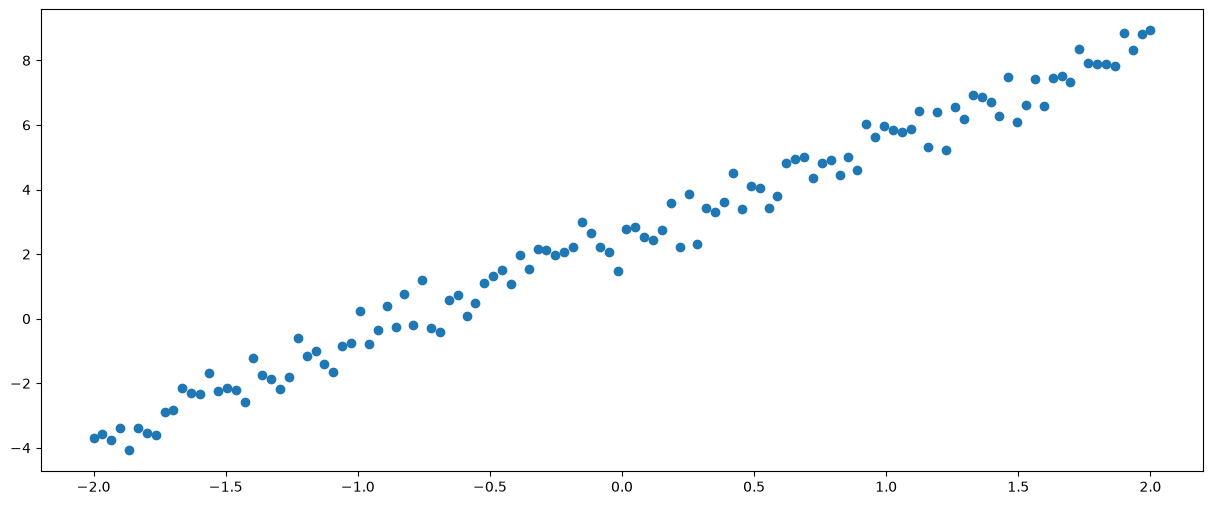

In [21]:
plt.figure(figsize=(15, 6))
plt.scatter(x.cpu(), y.cpu(), alpha=0.8)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Nuage de points genere : y = 3x + 2 + bruit")
plt.grid(True)
plt.show()

In [22]:
import torch.nn as nn

In [23]:
model = nn.Linear(1, 1).to(device)

In [33]:
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.05)
epochs = 500
losses = []

In [34]:
model.train()

for epoch in range(epochs):
    y_pred = model(x)
    loss = loss_function(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item():.4f}")

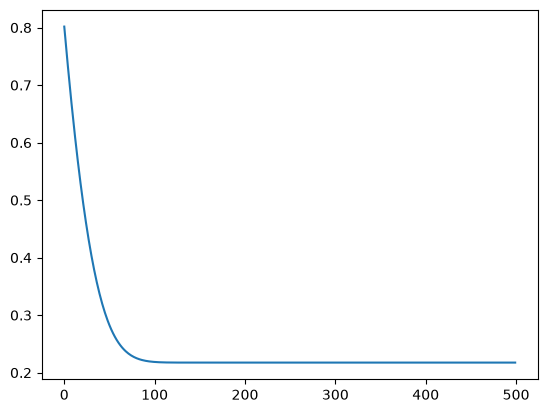

In [35]:
plt.figure(figsize=(8, 5))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSELoss")
plt.title("Evolution de la perte")
plt.grid(True)
plt.show()

In [27]:
print(f"Perte finale : {losses[-1]:.4f}")

In [28]:
model.eval()

with torch.inference_mode():
    y_pred = model(x)

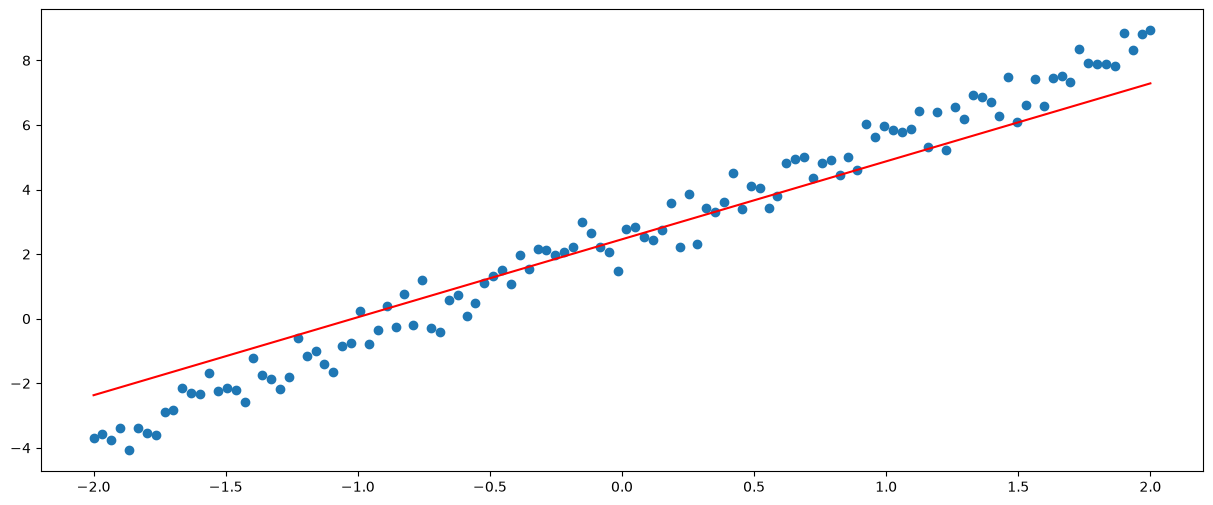

In [29]:
plt.figure(figsize=(15, 6))
plt.scatter(x.cpu(), y.cpu(), alpha=0.8, label="Donnees")
plt.plot(x.cpu(), y_pred.cpu(), color="red", label="Droite apprise")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Regression lineaire avec PyTorch")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
ss_res = torch.sum((y - y_pred) ** 2)
ss_tot = torch.sum((y - y.mean()) ** 2)
score = 1 - ss_res / ss_tot

print(f"R² Score : {score.item():.4f}")

R² Score: 0.9383463859558105


In [31]:
poids = model.weight.item()
biais = model.bias.item()

print(f"Poids appris w : {poids:.4f}")
print(f"Biais appris b : {biais:.4f}")
print("Valeurs attendues approximatives : w = 3, b = 2")

In [32]:
x_nouveau = torch.tensor([[1.5]], device=device)

model.eval()
with torch.inference_mode():
    prediction = model(x_nouveau)

print(f"Prediction pour x = 1.5 : {prediction.item():.4f}")

tensor(0.9383)


In [ ]:
# Etapes importantes vues dans la video :
# 1. Mettre le modele en mode entrainement avec model.train().
# 2. Faire le forward : y_pred = model(x).
# 3. Calculer la perte : loss = loss_function(y_pred, y).
# 4. Reinitialiser les gradients : optimizer.zero_grad().
# 5. Calculer les gradients : loss.backward().
# 6. Mettre a jour les parametres : optimizer.step().
# 7. En evaluation, utiliser model.eval() et torch.inference_mode().